### 1. Load libraries

In [1]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation
from processing.database import references

### 2. Analysis of raw data

In [2]:
phi_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIMThermodynamics\UNIFACDortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


TypeError: ExperimentalValidation._preprocess_data() missing 1 required positional argument: 'raw_data'

##### 2.1 General analysis of the database

In [ ]:
references_tuple = [(key, value[0], value[1]) for key, value in references.items()]
references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])

In [4]:
references_df.shape[0]

84

In [5]:
references_df.select(pl.col('Oil')).unique().shape[0]

54

In [6]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
25.736842


In [7]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
10.330986


In [8]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [9]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

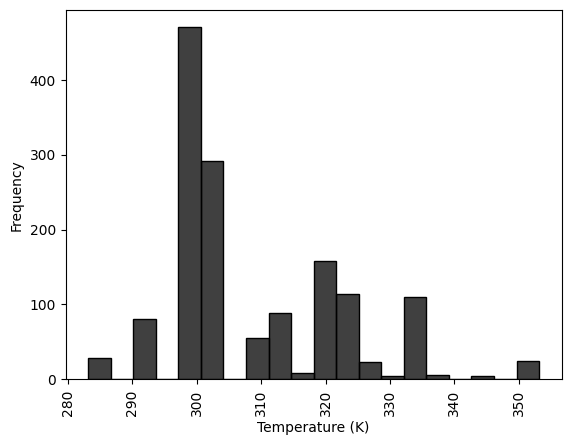

In [10]:
sns.histplot(data = phi_data, x = 'Temperature (K)', color = 'black').set(ylabel = 'Frequency')
plt.xticks(rotation = 90)
plt.show()

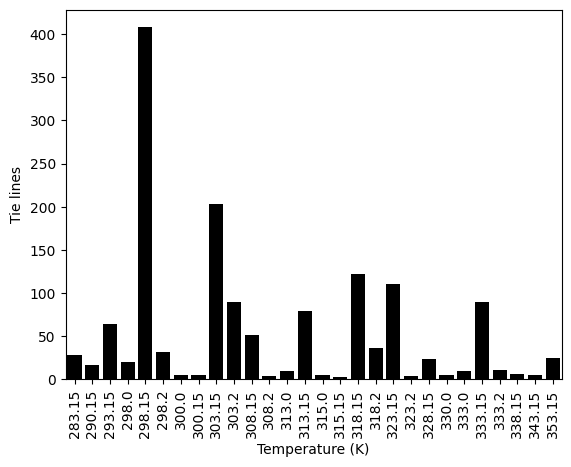

In [11]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len', color='black').set(ylabel='Tie lines')
plt.xticks(rotation = 90)
plt.show()

In [12]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,431
2,966
3,6
4,18


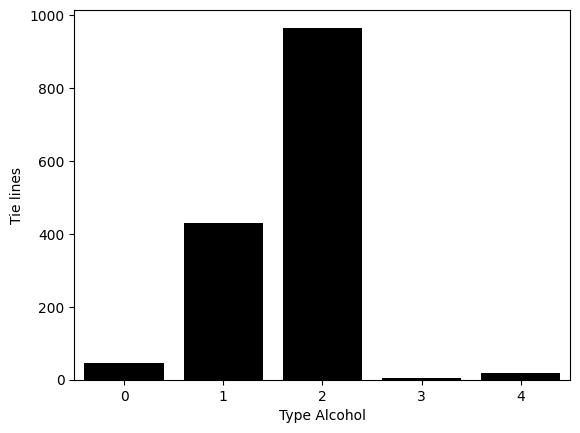

In [13]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len', color='black').set(ylabel='Tie lines')
plt.show()

In [14]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [15]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)
    
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

In [16]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)


##### 2.2 Statistical analysis of the data

In [17]:

df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1467.0,1467.0,"""1467""",1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",733.0,32.74983,null,308.490048,1.67212,0.178024,0.131576,0.360306,0.240804,0.007254,0.00111,0.023056,0.057538,0.399367,0.005744,0.135025,0.424681,0.001278,0.00068,0.024127,0.009191,0.012275,0.229089,0.580317,0.045971,0.000837,0.001506,0.022334,0.107611,NaN,NaN,NaN,0.278948,-inf,0.020075,NaN,NaN,NaN,null,NaN
"""std""",423.630735,14.862241,null,13.754783,0.604265,0.209426,0.183292,0.160971,0.228252,0.056253,0.006553,0.045024,0.118605,0.440863,0.013351,0.135914,0.408361,0.006648,0.004399,0.04839,0.032124,0.037566,0.314191,0.293656,0.110696,0.004325,0.008787,0.042786,0.217756,NaN,NaN,NaN,0.267055,NaN,0.096718,NaN,NaN,NaN,null,NaN
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-26.542169,-0.160734,-inf,-0.333333,-3.2,-0.008,-inf,null,0.0
"""25%""",367.0,23.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.3296,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379947,0.0,0.0,0.0,0.0,0.0,0.416374,null,0.005922
"""50%""",733.0,35.0,null,303.15,2.0,0.0,0.0,0.4367,0.327,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1006,0.5813,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.656,0.0031,0.0,0.0,0.0,0.0,0.0,0.0,0.495118,0.444153,0.0,0.0,0.0,0.0,0.495811,null,0.01592
"""75%""",1100.0,45.0,null,318.15,2.0,0.3637,0.3,0.475,0.4695,0.0,0.0,0.0248,0.0607,0.89617,0.00525,0.1711,0.84227,1.0000e-20,1.0000e-20,0.0264,0.0063,0.0121,0.4991,0.8424,0.0461,0.0,0.0,0.0251,0.1104,0.426625,0.377542,0.529954,0.525158,0.0,0.0,0.476923,0.525823,0.543767,null,0.051567
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.8698,0.6355,0.7005,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,1000.0,inf,1.801711,7.0050e19,0.590909,21.0,0.949069,inf,null,1.8862e19


In [18]:

df.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
u32,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[f64],f64
7,2,"""a""",293.15,2,0.4902,0.4768,0.033,0.0,0.0,0.0,0.0,0.0,0.9305,0.0219,0.0476,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0248,0.9309,0.0443,0.0,0.0,0.0,0.0,0.0,0.513857,0.49956,-3.424242,0.0,0.0,0.0,0.0,0.0,-0.803609,"[1.317465, 1.303169, … null]",1.747089
121,8,"""a""",333.15,1,0.4156,0.4249,0.1595,0.0,0.0,0.0,0.0,0.0,0.9901,0.0013,0.0086,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.011,0.9279,0.0611,0.0,0.0,0.0,0.0,0.0,0.413237,0.542845,-1.874286,0.0,0.0,0.0,0.0,0.0,-0.306068,"[0.719305, 0.848913, … null]",1.045478
235,14,"""a""",328.15,1,0.25,0.384,0.366,0.0,0.0,0.0,0.0,0.0,0.5934,0.046,0.3606,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0557,0.5807,0.3636,0.0,0.0,0.0,0.0,0.0,0.361354,0.36787,-0.8,0.0,0.0,0.0,0.0,0.0,-0.023592,"[0.384946, 0.391462, … null]",0.517605
263,17,"""a""",298.15,2,0.669,0.261,0.07,0.0,0.0,0.0,0.0,0.0,0.921,0.011,0.067,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.938,0.062,0.0,0.0,0.0,0.0,0.0,0.726384,0.730313,1.6,0.0,0.0,0.0,0.0,0.0,1.018899,"[0.292515, 0.288586, … null]",0.387401
431,27,"""aa""",318.15,1,0.4995,0.5005,0.0001,0.0,0.0,0.0,0.0,0.0,0.9952,0.0048,0.0001,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0077,0.9923,0.0001,0.0,0.0,0.0,0.0,0.0,0.498025,0.498025,NaN,0.0,0.0,0.0,0.0,0.0,NaN,"[NaN, NaN, … null]",NaN
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1110,44,"""bb""",298.15,2,0.0,0.0,0.49,0.0,0.4718,0.0,0.0102,0.028,1.0000e-20,1.0000e-20,0.0897,0.8978,1.0000e-20,1.0000e-20,0.0097,0.0028,0.0,0.0,0.9143,0.0466,0.0,0.0,0.0113,0.0278,0.0,0.0,0.514553,-0.054746,4.7180e19,0.0,0.6875,-0.008,9.4360e18,"[null, null, … 9.4360e18]",1.5098e19
1111,44,"""bb""",298.15,2,0.0,0.0,0.4498,0.0,0.5192,0.0,0.0002,0.0308,1.0000e-20,1.0000e-20,0.0836,0.9137,1.0000e-20,1.0000e-20,0.0002,0.0025,0.0,0.0,0.9253,0.0165,0.0,0.0,0.0002,0.058,0.0,0.0,0.564928,-0.018391,5.1920e19,0.0,NaN,0.49009,NaN,"[null, null, … NaN]",NaN
1303,50,"""a""",303.2,2,0.0,0.0,0.499,0.393,0.005,0.0,0.102,0.0,1.0000e-20,1.0000e-20,0.26,0.657,0.006,1.0000e-20,0.078,1.0000e-20,0.0,0.0,0.673,0.193,0.006,0.0,0.129,0.0,0.0,0.0,0.421308,0.431034,-inf,0.0,0.529412,0.0,-inf,"[null, null, … null]",NaN


In [19]:
filtered_phi_df = df.filter((pl.col('Experimental mean phi') <=1) & (pl.col('Experimental mean phi') > 0))
filtered_phi_df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1413.0,1413.0,"""1413""",1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",729.032555,32.605803,null,308.60414,1.661005,0.178883,0.132316,0.360182,0.244741,0.001081,0.001152,0.023134,0.058165,0.402853,0.005801,0.135134,0.420655,0.001323,0.000706,0.024207,0.009415,0.012461,0.229169,0.579437,0.045871,0.000865,0.001563,0.022217,0.108352,0.210027,0.168215,0.444856,0.283201,0.022613,0.020842,0.200244,0.231378,0.476626,null,0.044519
"""std""",425.789228,14.980285,null,13.815078,0.590662,0.208694,0.182492,0.157658,0.22821,0.005528,0.006674,0.045575,0.118561,0.440484,0.013434,0.136128,0.408525,0.006768,0.00448,0.048987,0.032648,0.038159,0.310115,0.289097,0.111877,0.004401,0.008948,0.043114,0.216524,0.237506,0.228083,0.187893,0.262852,0.120434,0.098468,0.320021,0.267577,0.127825,null,0.083489
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.507519,0.0,-0.8125,-0.333333,-1.0,0.0,0.063604,null,0.0
"""25%""",357.0,22.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.332,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379121,0.0,0.0,0.0,0.0,0.0,0.415288,null,0.005415
"""50%""",725.0,35.0,null,303.15,2.0,0.0,0.0,0.4321,0.348,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1005,0.5786,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.6543,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.493178,0.461234,0.0,0.0,0.0,0.0,0.492668,null,0.014766
"""75%""",1092.0,45.0,null,318.15,2.0,0.3626,0.3,0.4749,0.4721,0.0,0.0,0.0245,0.061,0.8955,0.0054,0.171,0.84,1.0000e-20,1.0000e-20,0.0253,0.0064,0.0121,0.4991,0.8355,0.0449,0.0,0.0,0.0245,0.114,0.425669,0.37537,0.528979,0.525406,0.0,0.0,0.468354,0.525406,0.538778,null,0.043806
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.7689,0.6355,0.0586,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,0.874608,2.229878,0.778746,0.888889,0.590909,2.0,0.949069,0.927951,null,0.912044


##### 2.3 Distribution of experimental PHI for each component

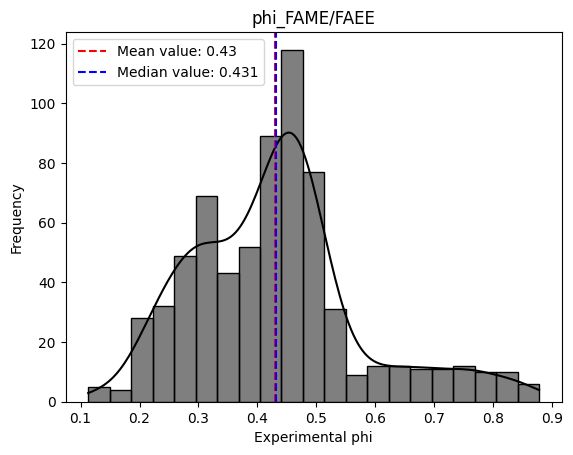

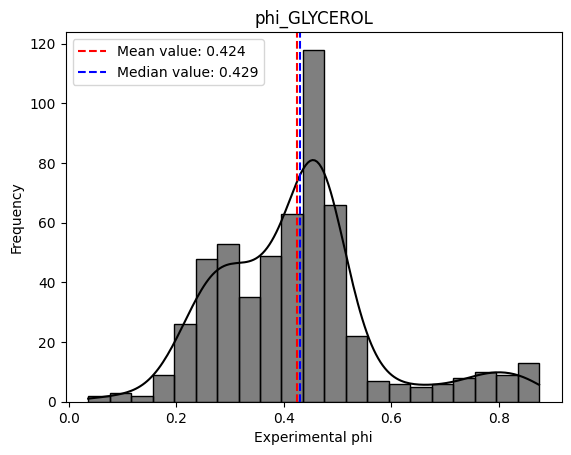

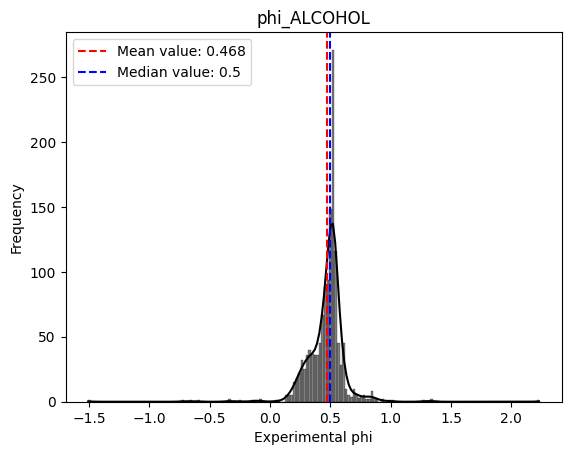

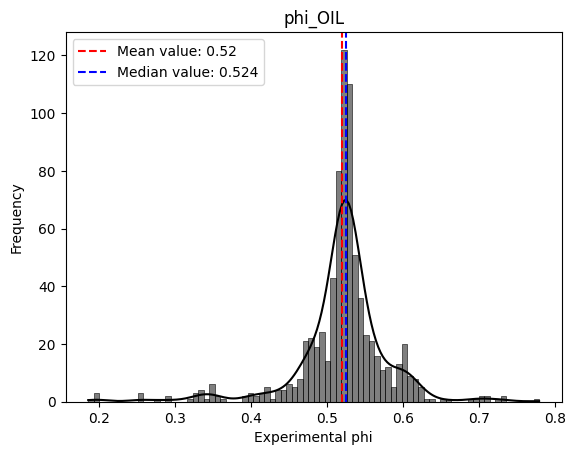

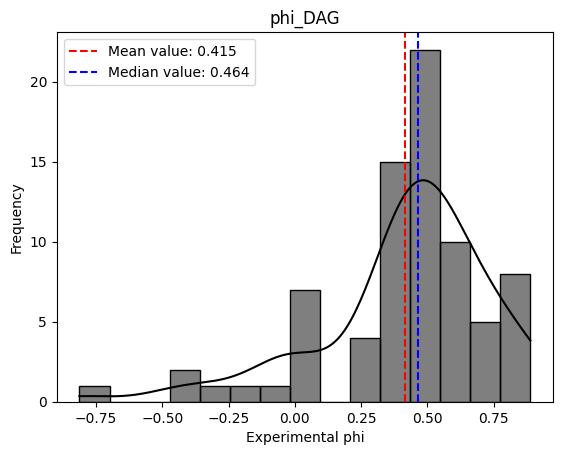

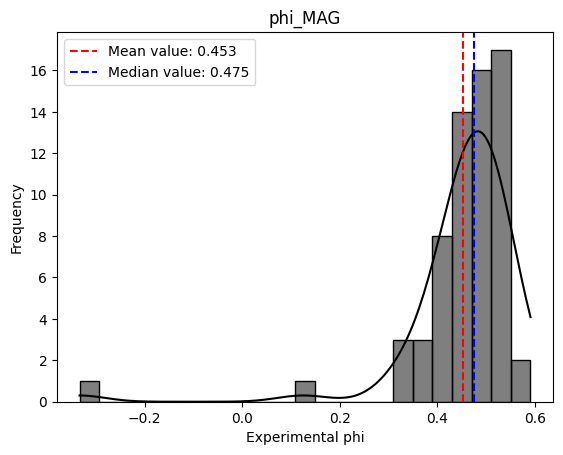

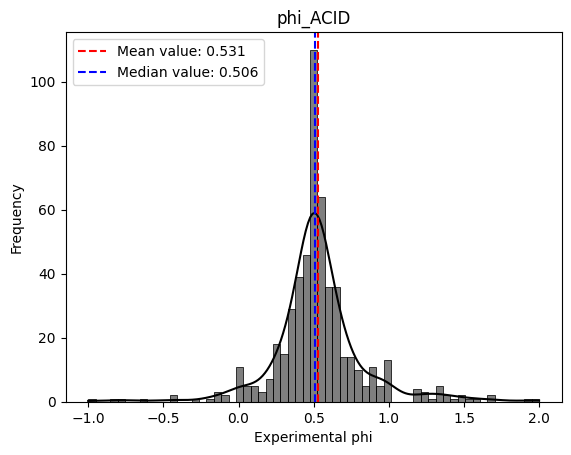

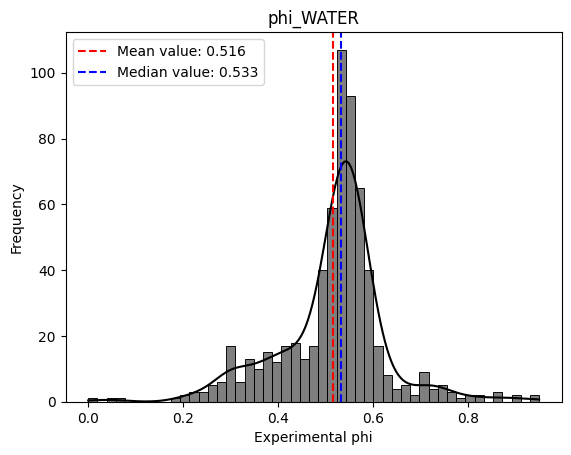

In [20]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=column_name, ylabel = 'Frequency', xlabel = 'Experimental phi')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

##### 2.4 Distribution of mean experimental phi per tie line

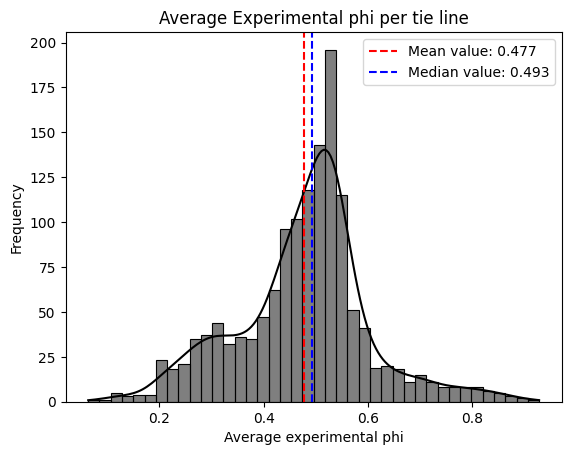

In [21]:
mean_value = filtered_phi_df.select(pl.col('Experimental mean phi')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('Experimental mean phi')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental phi per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental phi')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

##### 2.5 Distribution of average absolute error between the tie line experimental mean phi and each component phi 

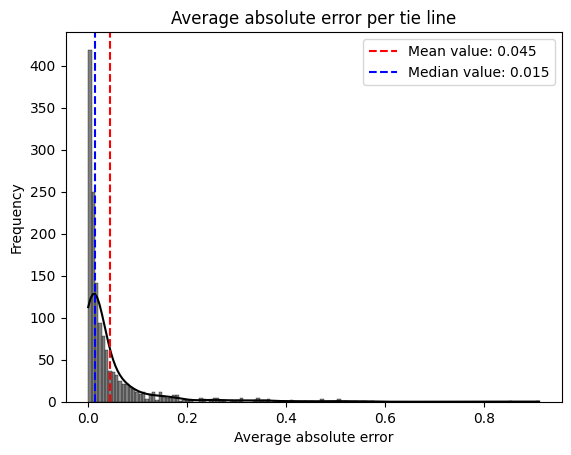

In [22]:
mean_value = filtered_phi_df.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('average_absolute_error')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average absolute error per tie line',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

### 3.Analysis of refined data

In [2]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data, phi_names = ExperimentalValidation(path_to_data=r'C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=i).validate_data()
    lengths.append(validated_data.shape[0])
    
    

##### 3.1 Effect of error threshold on filtered data

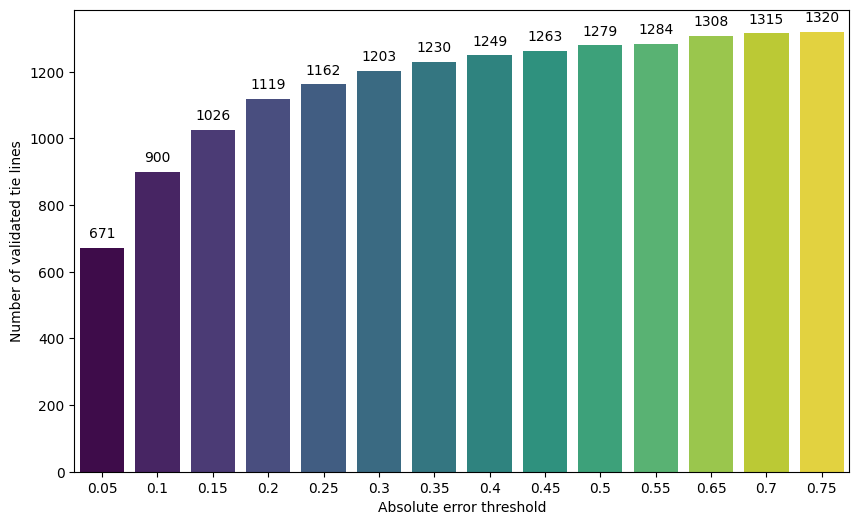

In [4]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Absolute error threshold')
ax.set_ylabel('Number of validated tie lines')

# Show the plot
plt.show()

##### 3.2 Statistical analysis of reconciled data and distribution of reconciled phi

In [25]:

refined_data = (pl.read_excel('data/refined_lle_data.xlsx', engine='calamine')).with_row_index()

In [26]:
refined_data.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.057055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,0.0,0.096617,0.0,0.0,0.0,0.0,0.0,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,0.0,0.0,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961
"""max""",1133.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999


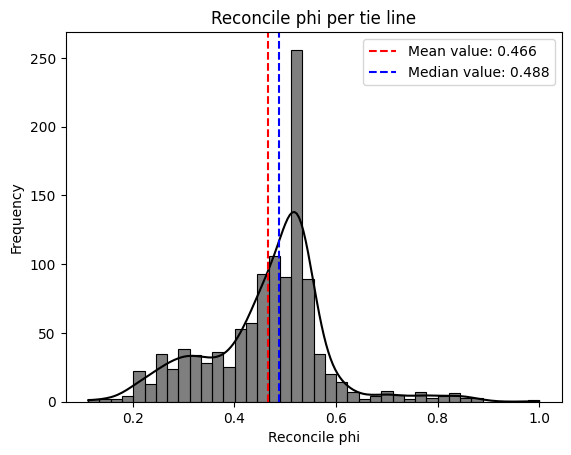

In [27]:
mean_value = refined_data.select(pl.col('Reconcile phi')).mean().to_numpy()[0][0]
median_value = refined_data.select(pl.col('Reconcile phi')).median().to_numpy()[0][0]
sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile phi per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile phi')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

In [28]:
refined_experimental_data = refined_data.select(pl.col(['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F',
                                                       'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 
                                                       'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']))

In [29]:

component_list = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
num_components = 8
refined_experimental_data = refined_experimental_data.with_columns( 
        
            [pl.when(pl.nth(i)==0.0)
            .then(1e-20)
            .otherwise(pl.nth(i))
            .alias(refined_experimental_data.columns[i])
            for i in range(num_components, num_components*2)]   # The parameters in the range function consider the columns with compositions of the light phase  
            
        )
        

In [30]:
refined_experimental_phi = refined_experimental_data.select(
            
            [((pl.nth(i) - pl.nth(i+num_components*2))/(pl.nth(i+num_components) - pl.nth(i+num_components*2)))
            .alias(f'phi_{component_list[i]}') 
            for i in range(0, num_components)]
        ).with_row_index()
        

In [31]:
refined_experimental_phi = refined_experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

In [32]:
refined_experimental_data = refined_experimental_data.with_row_index()

In [33]:
refined_total_data = refined_experimental_data.join(refined_experimental_phi, on = 'index')

In [34]:
refined_total_data.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1064,0.0,0.0,0.4704,0.5208,0.0088,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.177716,0.813416,0.0088,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.8999,0.0914,0.0088,0.0,0.0,0.0,0.0,0.0,0.594724,0.594724,NaN,0.0,0.0,0.0,NaN


In [35]:
refined_total_data = refined_total_data.filter(pl.col('index')!= 1064)

In [36]:
refined_total_data = refined_total_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

refined_total_data = refined_total_data.with_columns(
    refined_total_data['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

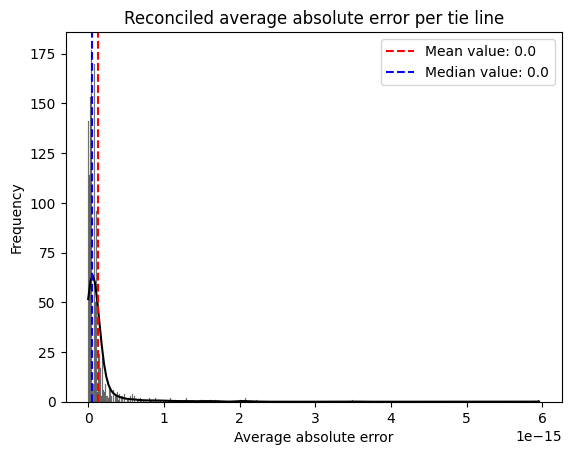

In [37]:
mean_value = refined_total_data.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = refined_total_data.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = refined_total_data.select(pl.col('average_absolute_error')).to_numpy().reshape(1133), kde = True, color='black').set(title = f'Reconciled average absolute error per tie line',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

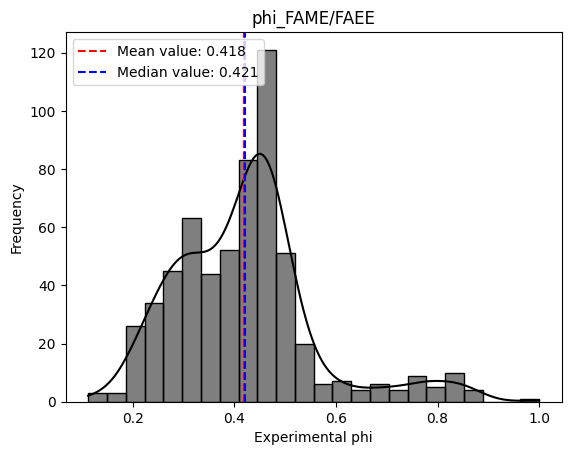

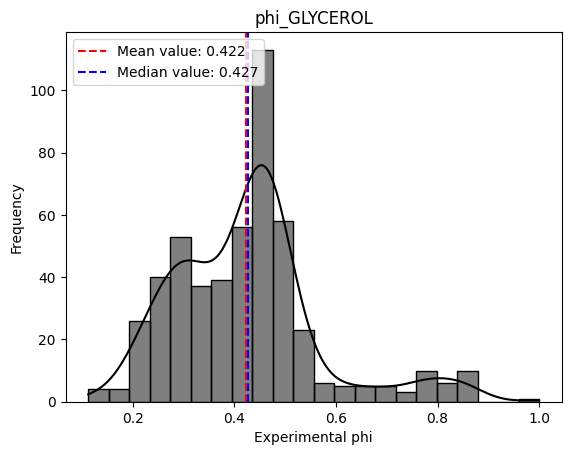

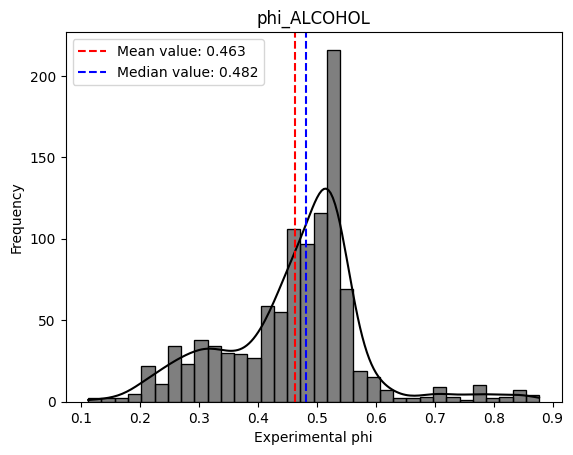

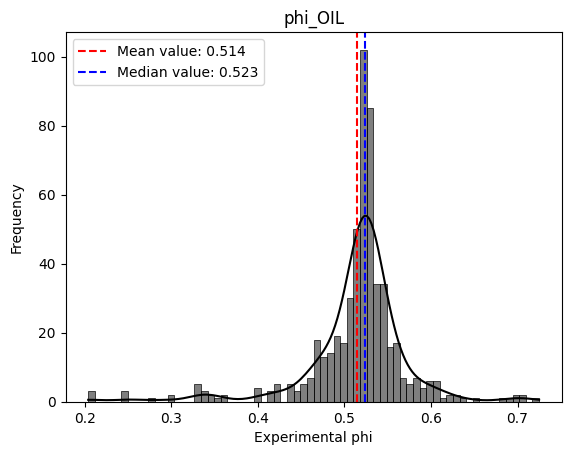

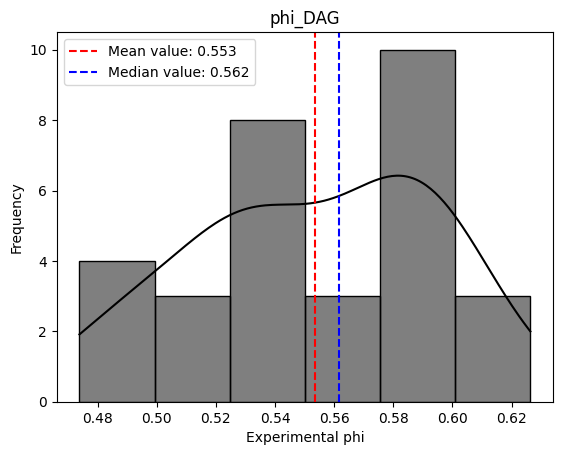

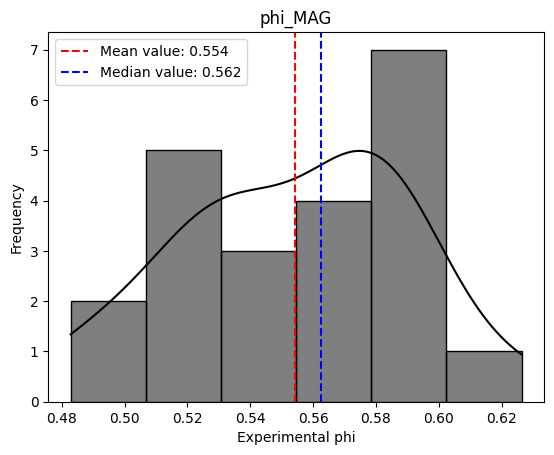

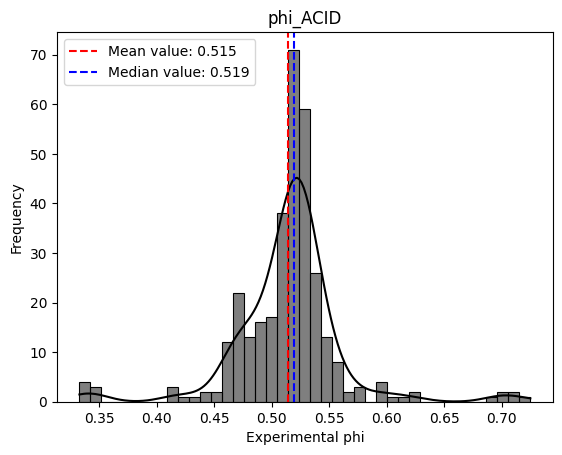

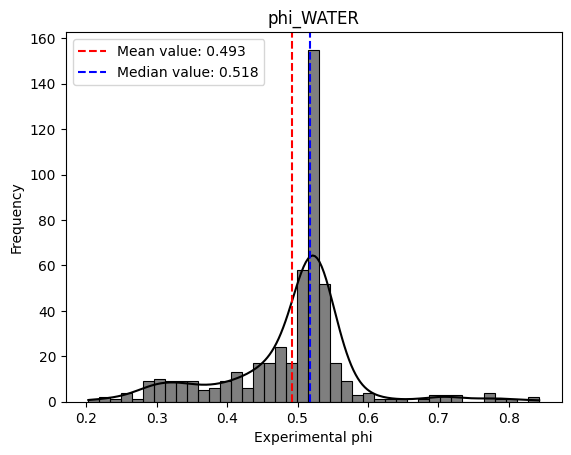

In [38]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=column_name, ylabel = 'Frequency', xlabel = 'Experimental phi')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

###  4. Source Data

In [2]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

from matplotlib import cm
from scipy.interpolate import griddata

In [3]:

df = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\SensitivityAnalysis\profile_coeffs_ref.xlsx")

In [4]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [5]:
stats_df = filtered_df.group_by('Source').agg([
    # For column 'm'
    pl.col('m').min().alias('m_min'),
    pl.col('m').quantile(0.25).alias('m_q25'),
    pl.col('m').median().alias('m_median'),
    pl.col('m').quantile(0.75).alias('m_q75'),
    pl.col('m').max().alias('m_max'),
    pl.col('m').mean().alias('m_mean'),
    
    # For column 'n'
    pl.col('n').min().alias('n_min'),
    pl.col('n').quantile(0.25).alias('n_q25'),
    pl.col('n').median().alias('n_median'),
    pl.col('n').quantile(0.75).alias('n_q75'),
    pl.col('n').max().alias('n_max'),
    pl.col('n').mean().alias('n_mean'),
    
    # For column 'p'
    pl.col('p').min().alias('p_min'),
    pl.col('p').quantile(0.25).alias('p_q25'),
    pl.col('p').median().alias('p_median'),
    pl.col('p').quantile(0.75).alias('p_q75'),
    pl.col('p').max().alias('p_max'),
    pl.col('p').mean().alias('p_mean'),
    
])

with pl.Config(tbl_rows=len(stats_df), tbl_cols=-1):
    print(stats_df)

shape: (40, 19)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Sou ┆ m_m ┆ m_q ┆ m_m ┆ m_q ┆ m_m ┆ m_m ┆ n_m ┆ n_q ┆ n_m ┆ n_q ┆ n_m ┆ n_m ┆ p_m ┆ p_q ┆ p_m ┆ p_q ┆ p_m ┆ p_m │
│ rce ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean │
│ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- │
│ str ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 │
│     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ Chi ┆ 14. ┆ 14. ┆ 14. ┆ 14. ┆ 14. ┆ 14. ┆ 0.6 ┆ 0.6 ┆ 0.6 ┆ 0.6 ┆ 0.6 ┆ 0.6 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 │
│ cha ┆ 352 ┆ 352 ┆ 352 ┆ 352 ┆ 352 ┆ 352 ┆ 414 ┆ 414 ┆ 

In [6]:
count_values = filtered_df.group_by('Source').agg(
    pl.col('m').count().alias('m_count')
)

count_values = count_values.sort(by="m_count", descending=True)

with pl.Config(tbl_rows=len(count_values)):
    print(count_values)

shape: (40, 2)
┌─────────────────────────────┬─────────┐
│ Source                      ┆ m_count │
│ ---                         ┆ ---     │
│ str                         ┆ u32     │
╞═════════════════════════════╪═════════╡
│ Soybean                     ┆ 13      │
│ Sunflower                   ┆ 7       │
│ Cottonseed                  ┆ 5       │
│ Corn                        ┆ 4       │
│ Castor                      ┆ 4       │
│ Rice Bran                   ┆ 3       │
│ Canola                      ┆ 3       │
│ Canola                      ┆ 3       │
│ Brazil Nut                  ┆ 2       │
│ Palm                        ┆ 2       │
│ Oleic                       ┆ 2       │
│ Crambe                      ┆ 2       │
│ Peanut                      ┆ 2       │
│ Jatropha                    ┆ 2       │
│ Macauba                     ┆ 2       │
│ Coconut                     ┆ 2       │
│ Babassu                     ┆ 2       │
│ Garlic                      ┆ 1       │
│ Triolein         

In [ ]:
df_pandas = filtered_df.to_pandas()
df_pandas

,Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Type Alcohol,m,n,p,b,Source
0,1,a,No,No,No,1,12.991240,1.043695,0.904216,0,Castor
1,2,a,No,No,No,2,12.888552,1.288996,0.000000,1,Cottonseed
2,3,a,No,No,No,2,15.900233,1.145124,0.000000,1,Crambe
3,4,a,No,No,No,1,12.951885,1.455246,0.000000,0,Sunflower
4,5,a,No,No,No,1,13.179053,1.357539,0.000000,0,Canola
...,...,...,...,...,...,...,...,...,...,...,...
78,55,c,No,No,No,2,13.316557,1.136814,0.000000,1,Rice Bran
79,56,a,No,No,No,1,12.844061,1.511330,0.000000,0,Sunflower
80,56,b,No,No,No,1,12.953540,1.422083,0.000000,0,10% Beef Tallow - Sunflower
81,56,c,No,No,No,1,13.062795,1.333019,0.000000,0,20% Beef Tallow - Sunflower


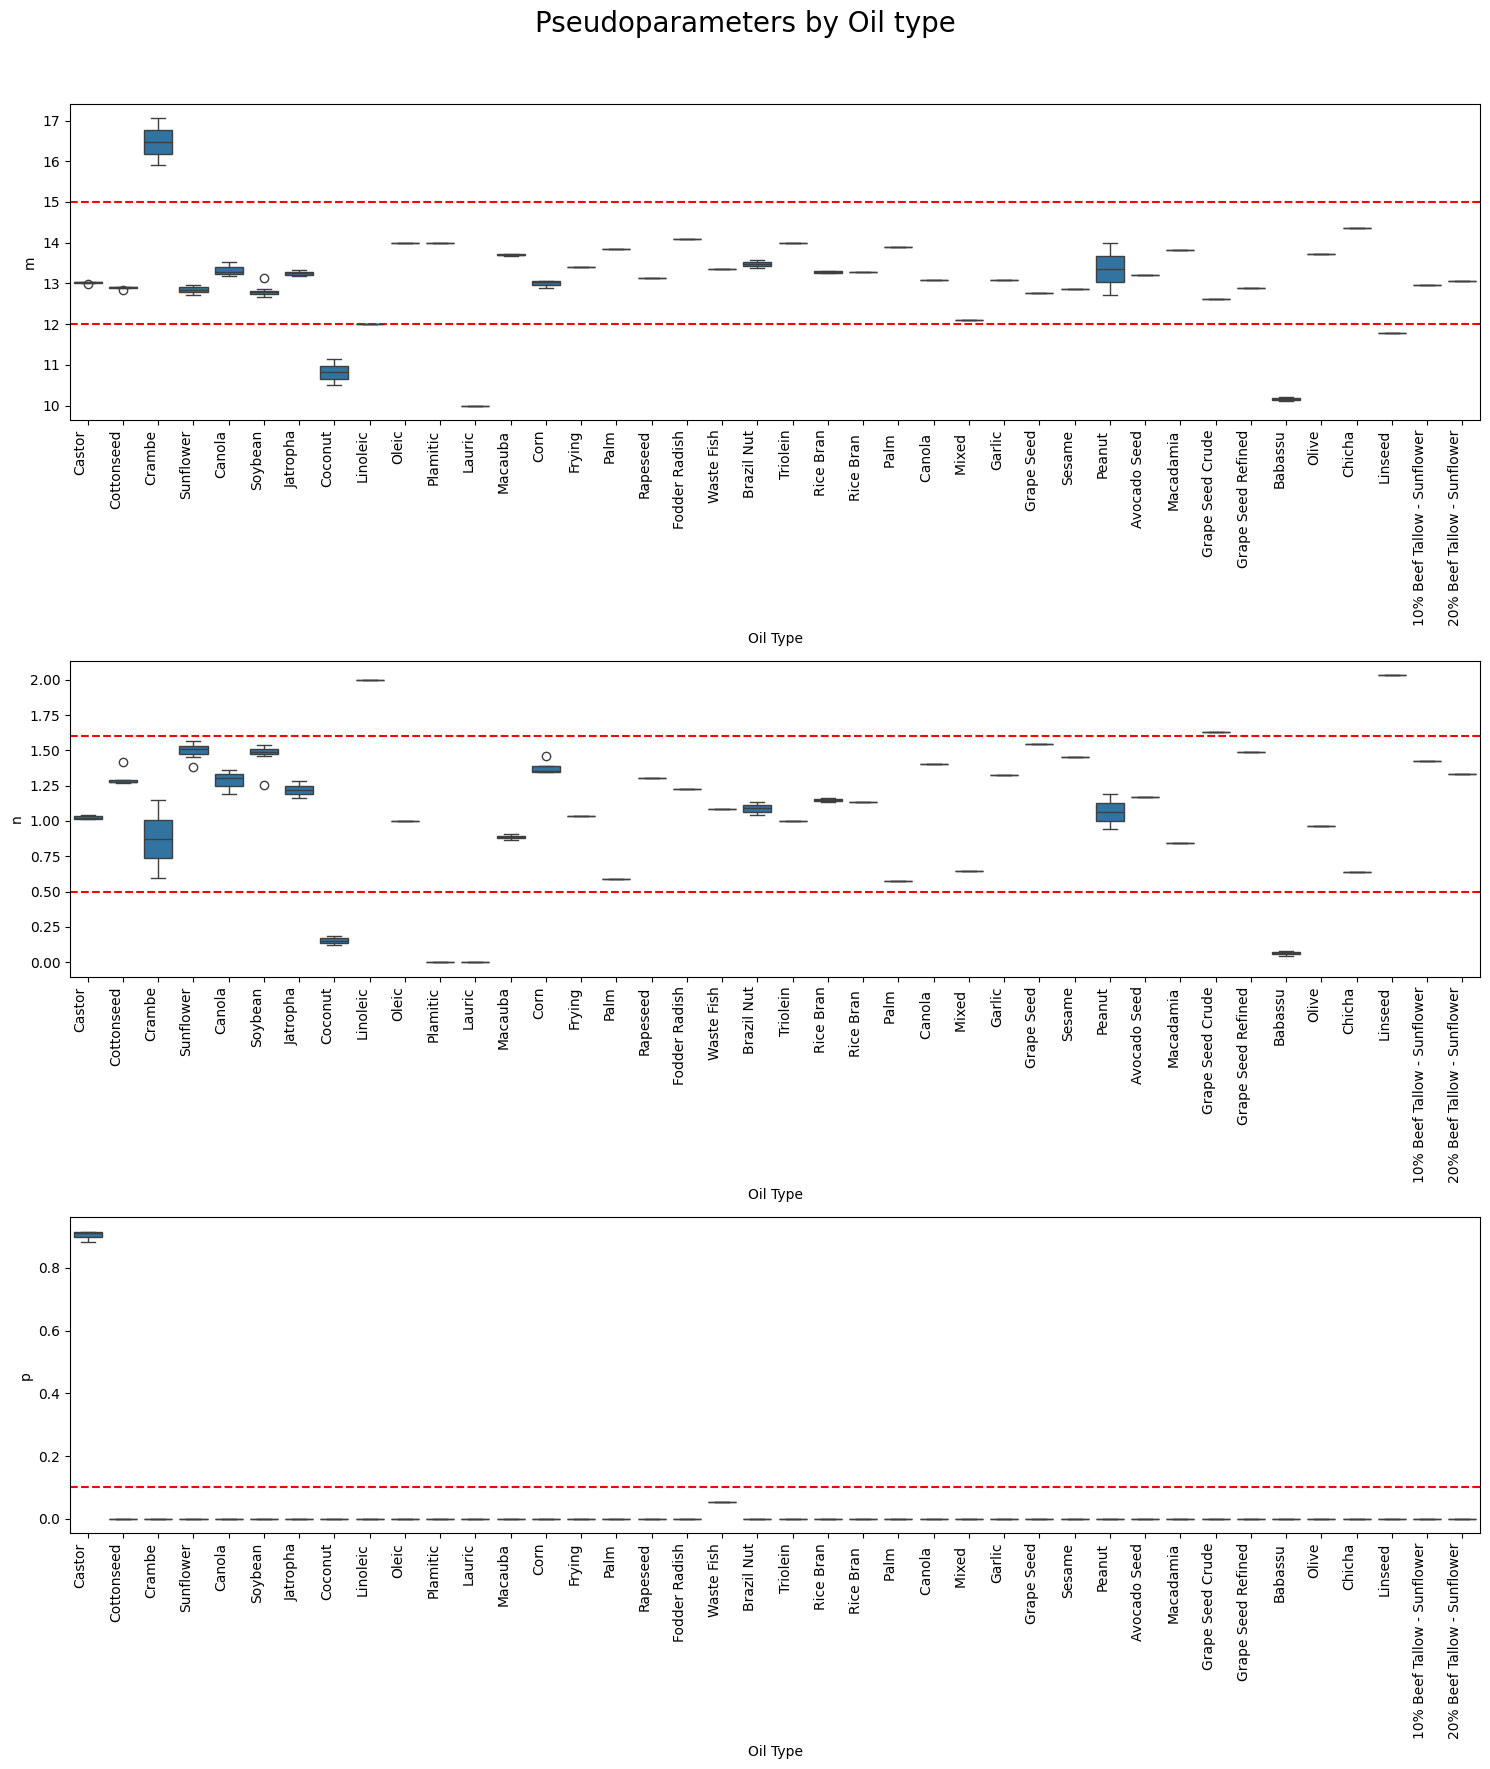

In [43]:

columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(3, 1, figsize=(15, 18))
fig.suptitle('Pseudoparameters by Oil type', fontsize=20)

axes = axes.flatten()

sns.boxplot(x='Source', y="m", data=df_pandas, ax=axes[0])
axes[0].set_xlabel('Oil Type')
axes[0].set_ylabel("m")
axes[0].axhline(y=12, color="red", linestyle="--")
axes[0].axhline(y=15, color="red", linestyle="--")
plt.setp(axes[0].get_xticklabels(), rotation=90, ha='right')

sns.boxplot(x='Source', y="n", data=df_pandas, ax=axes[1])
axes[1].set_xlabel('Oil Type')
axes[1].set_ylabel("n")
axes[1].axhline(y=1.6, color="red", linestyle="--")
axes[1].axhline(y=0.5, color="red", linestyle="--")
plt.setp(axes[1].get_xticklabels(), rotation=90, ha='right')

sns.boxplot(x='Source', y="p", data=df_pandas, ax=axes[2])
axes[2].set_xlabel('Oil Type')
axes[2].set_ylabel("p")
axes[2].axhline(y=0.1, color="red", linestyle="--")
plt.setp(axes[2].get_xticklabels(), rotation=90, ha='right')


plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [10]:
def surface_plot(X, Y, Z, title, x_label, y_label, z_label, bar_label):
    # Create a grid for interpolation
    X_grid = np.linspace(min(X), max(X), 50)
    Y_grid = np.linspace(min(Y), max(Y), 50)
    X_mesh, Y_mesh = np.meshgrid(X_grid, Y_grid)

    # Interpolate Z values onto the grid
    points = np.column_stack((X, Y))
    FAME_comp_grid = griddata(points, Z, (X_mesh, Y_mesh), method='linear')

    # Create a new figure
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Create surface plot
    surf = ax.plot_surface(X_mesh, Y_mesh, FAME_comp_grid, 
                        cmap='magma', 
                        edgecolor='none', 
                        alpha=0.8)


    # Add a color bar
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label=bar_label)

    # Add labels with your requested arrangement
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_zlabel(z_label)
    ax.set_title(title)

    # Adjust the viewing angle for better visualization
    ax.view_init(elev=30, azim=45)
    ax.set_box_aspect(None, zoom=0.85)

    plt.tight_layout()
    plt.show()

In [11]:
refined_data = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")

In [12]:
refined_data

Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""a""",298.15,1,0.4,0.4,0.2,0.0,0.0,0.0,0.0,0.0,0.881461,0.010995,0.106827,0.0,0.0,0.0,0.0,0.0,0.00001,0.723179,0.277407,0.0,0.0,0.0,0.0,0.0,0.453786
1,"""a""",298.15,1,0.385,0.385,0.23,0.0,0.0,0.0,0.0,0.0,0.856402,0.028158,0.115568,0.0,0.0,0.0,0.0,0.0,0.002266,0.674722,0.322908,0.0,0.0,0.0,0.0,0.0,0.448095
1,"""a""",298.15,1,0.41,0.41,0.18,0.0,0.0,0.0,0.0,0.0,0.90767,0.005553,0.086762,0.0,0.0,0.0,0.0,0.0,0.000146,0.74308,0.256786,0.0,0.0,0.0,0.0,0.0,0.451618
2,"""a""",293.15,2,0.4431,0.438,0.1189,0.0,0.0,0.0,0.0,0.0,0.895378,0.024504,0.080139,0.0,0.0,0.0,0.0,0.0,0.026639,0.818751,0.154592,0.0,0.0,0.0,0.0,0.0,0.479386
2,"""a""",293.15,2,0.4176,0.4162,0.1662,0.0,0.0,0.0,0.0,0.0,0.873731,0.023739,0.102309,0.0,0.0,0.0,0.0,0.0,0.025474,0.75359,0.221126,0.0,0.0,0.0,0.0,0.0,0.462273
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
57,"""a""",318.2,2,0.0,0.0,0.447,0.513,0.0,0.0,0.0,0.041,0.0,0.0,0.109755,0.888876,0.0,0.0,0.0,0.002904,0.0,0.0,0.866894,0.045007,0.0,0.0,0.0,0.088432,0.55458
57,"""a""",318.2,2,0.0,0.0,0.494,0.496,0.0,0.0,0.0,0.01,0.0,0.0,0.342187,0.651845,0.0,0.0,0.0,0.005811,0.0,0.0,0.718954,0.265071,0.0,0.0,0.0,0.016207,0.597065
57,"""a""",318.2,2,0.0,0.0,0.501,0.479,0.0,0.0,0.0,0.02,0.0,0.0,0.239539,0.754497,0.0,0.0,0.0,0.006396,0.0,0.0,0.818388,0.144574,0.0,0.0,0.0,0.036514,0.548309


In [13]:
comps_MW = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx")

In [14]:
comps_MW

Ref,Sub Ref,Type Alcohol,MW_FAME/FAEE,MW_Glycerol,MW_Alcohol,MW_Oil,MW_DAG,MW_MAG,MW_FA,MW_H2O
i64,str,i64,f64,f64,f64,f64,f64,f64,f64,i64
1,"""a""",1,324.139909,92.09,32.04,968.419726,659.279817,350.139909,296.139909,18
2,"""a""",2,315.953619,92.09,46.07,901.860858,614.907238,327.953619,273.953619,18
3,"""a""",2,354.376491,92.09,46.07,1017.129472,691.752981,366.376491,312.376491,18
4,"""a""",1,307.1628,92.09,32.04,917.488401,625.3256,333.1628,279.1628,18
5,"""a""",1,307.802762,92.09,32.04,919.408285,626.605523,333.802762,279.802762,18
…,…,…,…,…,…,…,…,…,…,…
55,"""c""",2,317.988974,92.09,46.07,907.966921,622.779458,331.889729,275.988974,18
56,"""a""",1,307.111442,92.09,32.04,917.334327,625.222885,333.111442,279.111442,18
56,"""b""",1,306.323727,92.09,32.04,914.971182,623.647455,332.323727,278.323727,18


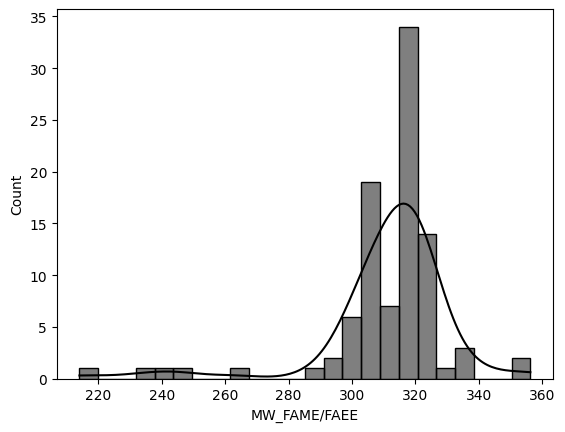

In [15]:
sns.histplot(x = comps_MW["MW_FAME/FAEE"], color="black", kde=True)
plt.show()

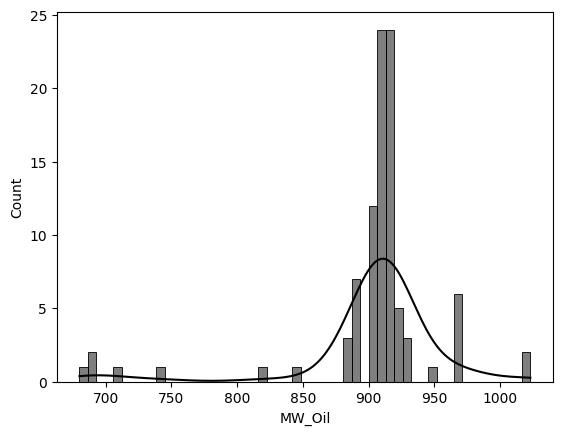

In [16]:

sns.histplot(x = comps_MW["MW_Oil"], color="black", kde=True)
plt.show()

In [17]:
refined_data = refined_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [18]:
refined_data

Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""a""",298.15,1,0.4,0.4,0.2,0.0,0.0,0.0,0.0,0.0,0.881461,0.010995,0.106827,0.0,0.0,0.0,0.0,0.0,0.00001,0.723179,0.277407,0.0,0.0,0.0,0.0,0.0,0.453786
1,"""a""",298.15,1,0.385,0.385,0.23,0.0,0.0,0.0,0.0,0.0,0.856402,0.028158,0.115568,0.0,0.0,0.0,0.0,0.0,0.002266,0.674722,0.322908,0.0,0.0,0.0,0.0,0.0,0.448095
1,"""a""",298.15,1,0.41,0.41,0.18,0.0,0.0,0.0,0.0,0.0,0.90767,0.005553,0.086762,0.0,0.0,0.0,0.0,0.0,0.000146,0.74308,0.256786,0.0,0.0,0.0,0.0,0.0,0.451618
2,"""a""",293.15,2,0.4431,0.438,0.1189,0.0,0.0,0.0,0.0,0.0,0.895378,0.024504,0.080139,0.0,0.0,0.0,0.0,0.0,0.026639,0.818751,0.154592,0.0,0.0,0.0,0.0,0.0,0.479386
2,"""a""",293.15,2,0.4176,0.4162,0.1662,0.0,0.0,0.0,0.0,0.0,0.873731,0.023739,0.102309,0.0,0.0,0.0,0.0,0.0,0.025474,0.75359,0.221126,0.0,0.0,0.0,0.0,0.0,0.462273
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
57,"""a""",318.2,2,0.0,0.0,0.447,0.513,0.0,0.0,0.0,0.041,0.0,0.0,0.109755,0.888876,0.0,0.0,0.0,0.002904,0.0,0.0,0.866894,0.045007,0.0,0.0,0.0,0.088432,0.55458
57,"""a""",318.2,2,0.0,0.0,0.494,0.496,0.0,0.0,0.0,0.01,0.0,0.0,0.342187,0.651845,0.0,0.0,0.0,0.005811,0.0,0.0,0.718954,0.265071,0.0,0.0,0.0,0.016207,0.597065
57,"""a""",318.2,2,0.0,0.0,0.501,0.479,0.0,0.0,0.0,0.02,0.0,0.0,0.239539,0.754497,0.0,0.0,0.0,0.006396,0.0,0.0,0.818388,0.144574,0.0,0.0,0.0,0.036514,0.548309


In [19]:
result = refined_data.join(
    comps_MW,
    on=["Ref", "Sub Ref"],
    how="left"
)

In [86]:
base_columns = [
    'FAME/FAEE',
    'GLYCEROL',
    'ALCOHOL',
    'OIL',
    'DAG',
    'MAG',
    'ACID',
    'WATER'
]

# Create the K_ columns with the condition: if _H is 0, then K_ is 0
for col in base_columns:
    col_l = f"{col}_L"
    col_h = f"{col}_H"
    k_col = f"K_{col}"
    
    # Using when/then/otherwise for conditional logic
    result = result.with_columns(
        pl.when(pl.col(col_h) == 0)
        .then(pl.lit(0))
        .otherwise(np.log(pl.col(col_l) / pl.col(col_h)))
        .alias(k_col)
    )
    
    


In [87]:
k_columns = [
    'K_FAME/FAEE',
    'K_GLYCEROL',
    'K_ALCOHOL',
    'K_OIL',
    'K_DAG',
    'K_MAG', 
    'K_ACID',
    'K_WATER'
]

if isinstance(result, pl.DataFrame):
    pdf = result.to_pandas()
else:
    pdf = result  # Assume it's already pandas

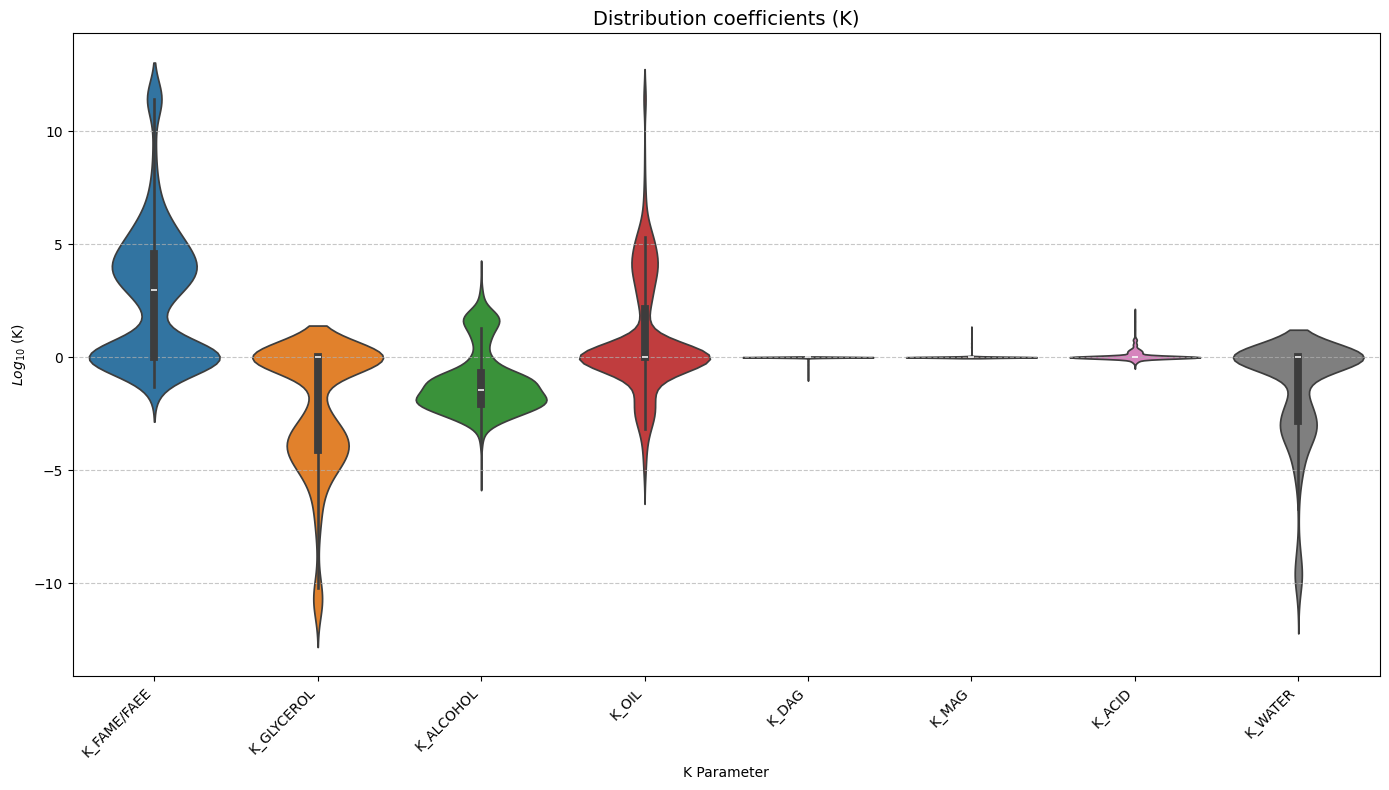

In [88]:
k_values_melted = pd.melt(pdf[k_columns], var_name='K Parameter', value_name='Value')

plt.figure(figsize=(14, 8))
sns.violinplot(hue='K Parameter', x = "K Parameter", y='Value', data=k_values_melted, legend=False)
plt.title('Distribution coefficients (K)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylabel("$Log_{10}$ (K)")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Handle outliers for the combined plot
q1, q3 = np.percentile(k_values_melted['Value'].dropna(), [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
#plt.ylim(0, min(k_values_melted['Value'].max(), upper_limit*1.5))

#plt.ylim(0, 30)

#plt.savefig('k_values_combined_violin.png', dpi=300, bbox_inches='tight')
plt.show()



In [164]:
K_FAME_df  = result.filter(pl.col("K_FAME/FAEE") > 0).drop(["Ref", "Sub Ref", "new sub ref"]).to_pandas()
K_FAME_corr = K_FAME_df.corr()[["K_FAME/FAEE"]]


In [170]:
K_FAME_df

,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,...,MW_FA,MW_H2O,K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER
0,293.15,2,0.4431,0.4380,0.1189,0.0,0.0,0.0,0.0,0.0,...,273.953619,18,33.611953,0.029928,0.518388,0.0,0.0,0.0,0.0,0.0
1,293.15,2,0.4176,0.4162,0.1662,0.0,0.0,0.0,0.0,0.0,...,273.953619,18,34.299384,0.031502,0.462674,0.0,0.0,0.0,0.0,0.0
2,293.15,2,0.4005,0.3935,0.2060,0.0,0.0,0.0,0.0,0.0,...,273.953619,18,35.890778,0.032542,0.438611,0.0,0.0,0.0,0.0,0.0
3,293.15,2,0.3711,0.3734,0.2555,0.0,0.0,0.0,0.0,0.0,...,273.953619,18,37.386470,0.035949,0.398549,0.0,0.0,0.0,0.0,0.0
4,313.15,2,0.4637,0.4711,0.0652,0.0,0.0,0.0,0.0,0.0,...,273.953619,18,33.389727,0.024296,0.502501,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
322,318.15,1,0.2520,0.2491,0.4989,0.0,0.0,0.0,0.0,0.0,...,278.323727,18,48.116207,0.011174,0.108020,0.0,0.0,0.0,0.0,0.0
323,298.15,1,0.2476,0.2482,0.5042,0.0,0.0,0.0,0.0,0.0,...,277.537625,18,44.002641,0.010036,0.131000,0.0,0.0,0.0,0.0,0.0
324,308.15,1,0.3494,0.3507,0.2998,0.0,0.0,0.0,0.0,0.0,...,277.537625,18,66.400386,0.011675,0.101797,0.0,0.0,0.0,0.0,0.0
325,308.15,1,0.2999,0.2999,0.4002,0.0,0.0,0.0,0.0,0.0,...,277.537625,18,61.908936,0.007780,0.104155,0.0,0.0,0.0,0.0,0.0


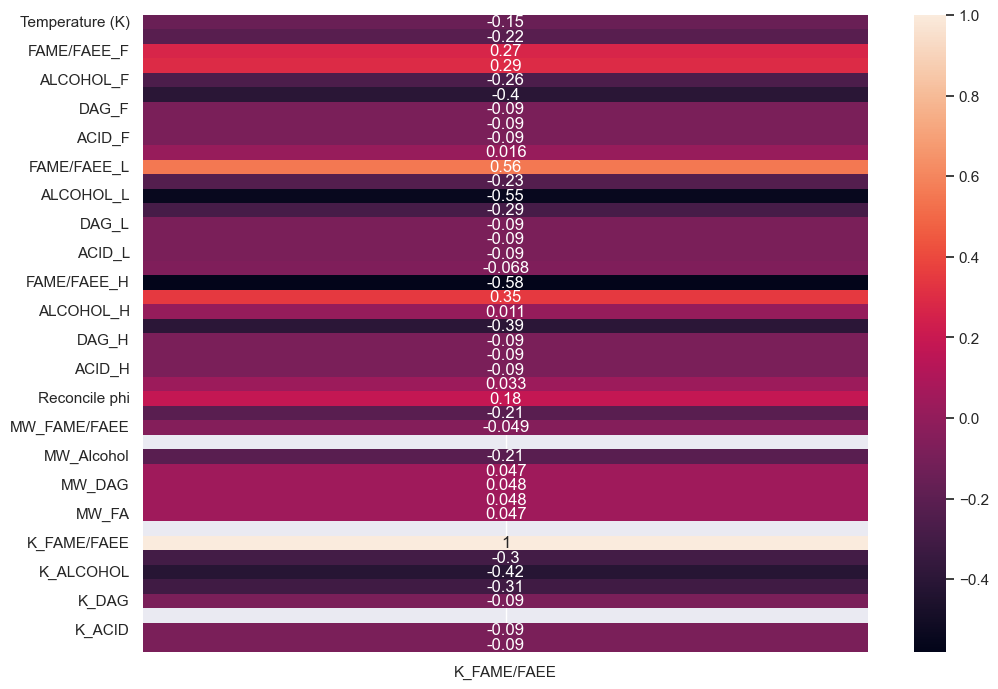

In [168]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_FAME_corr, annot=True)
plt.show()

In [233]:
K_OIL_df  = result.filter(pl.col("K_OIL") > 0).drop(["Ref", "Sub Ref", "new sub ref"]).to_pandas()
K_OIL_corr = K_OIL_df.corr()[["K_OIL"]]



In [235]:

K_OIL_corr

,K_OIL
Temperature (K),-0.177851
Type Alcohol,0.079123
FAME/FAEE_F,-0.160060
GLYCEROL_F,NaN
ALCOHOL_F,-0.304470
OIL_F,0.140050
DAG_F,-0.147428
MAG_F,-0.139858
ACID_F,-0.012789
WATER_F,0.693840


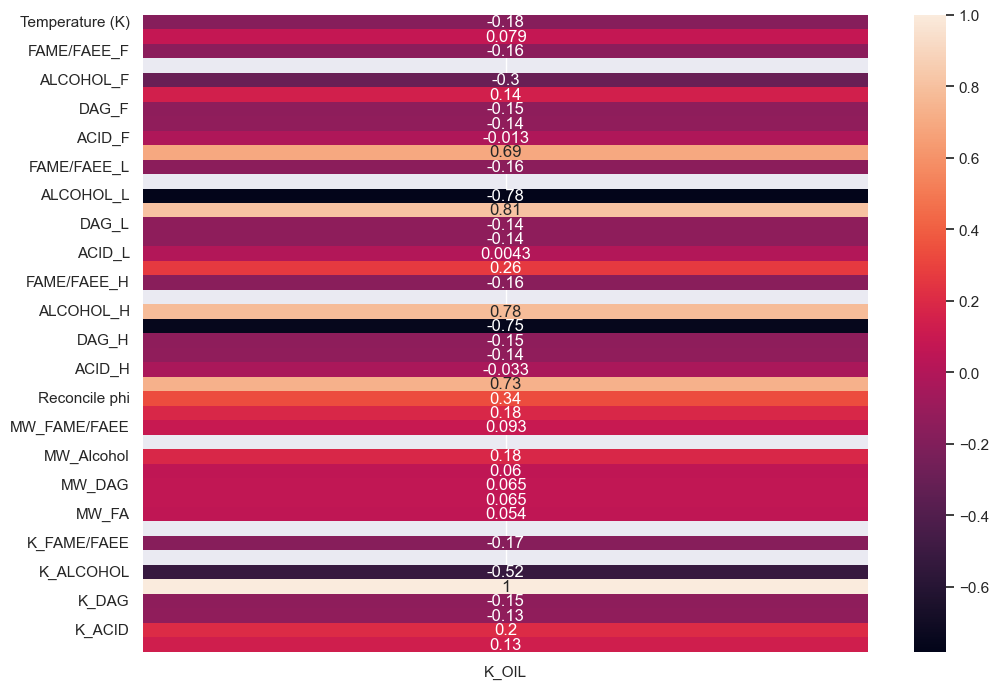

In [234]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_OIL_corr, annot=True)
plt.show()

In [176]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

In [220]:
X = K_FAME_df[["Temperature (K)", "FAME/FAEE_F", "ALCOHOL_F", "GLYCEROL_F"]].to_numpy()
y = K_FAME_df[["K_FAME/FAEE"]].to_numpy()

In [228]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [229]:
degree = 4
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
RE = np.mean(abs((y_pred_train - y)/y*100))
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.4792 RMSE: 16.2634


In [230]:
np.mean(np.abs((y - y_pred_train)/y * 100))

139.35009625835946

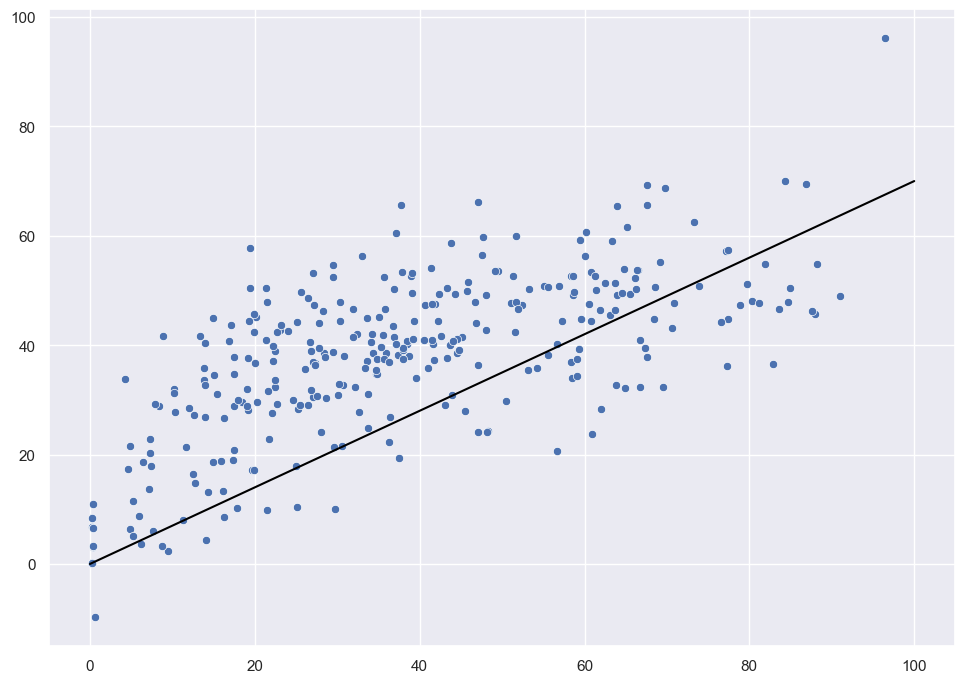

In [231]:
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]))
sns.lineplot(x = [0, 100], y = [0, 70], color = "black")
plt.show()

In [243]:
X = K_OIL_df[["OIL_F", "ACID_F", "WATER_F", "ALCOHOL_F"]].to_numpy()
y = K_OIL_df[["K_OIL"]].to_numpy()

In [244]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)



Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [245]:
degree = 4
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.7988 RMSE: 10.8879


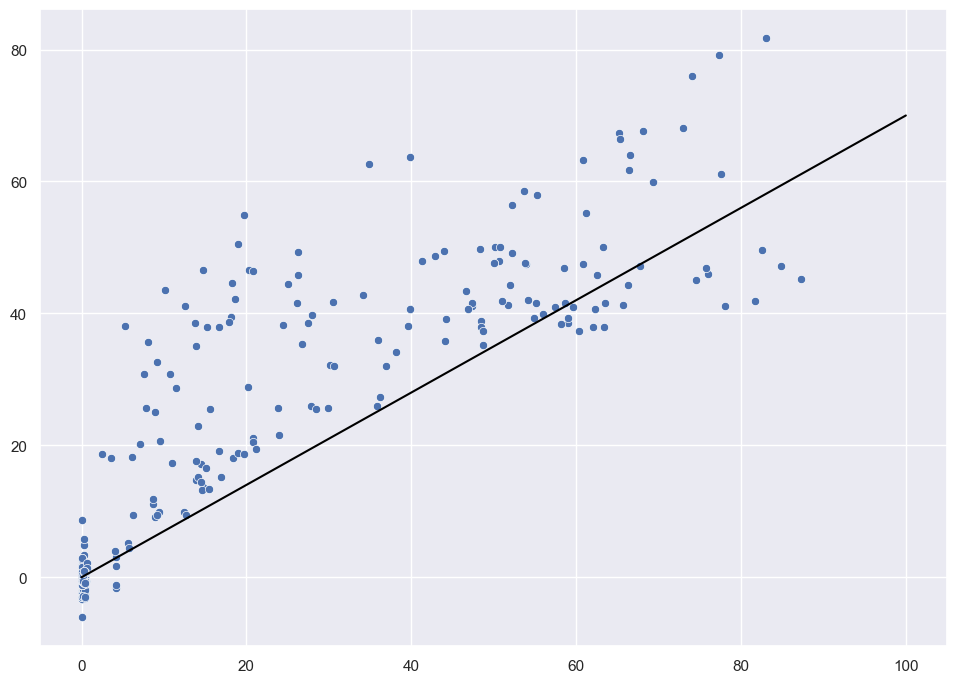

In [246]:
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]))
sns.lineplot(x = [0, 100], y = [0, 70], color = "black")
plt.show()

### 5. Surface plots

In [149]:
result_np = result.drop(["Sub Ref", "new sub ref"]).to_numpy()


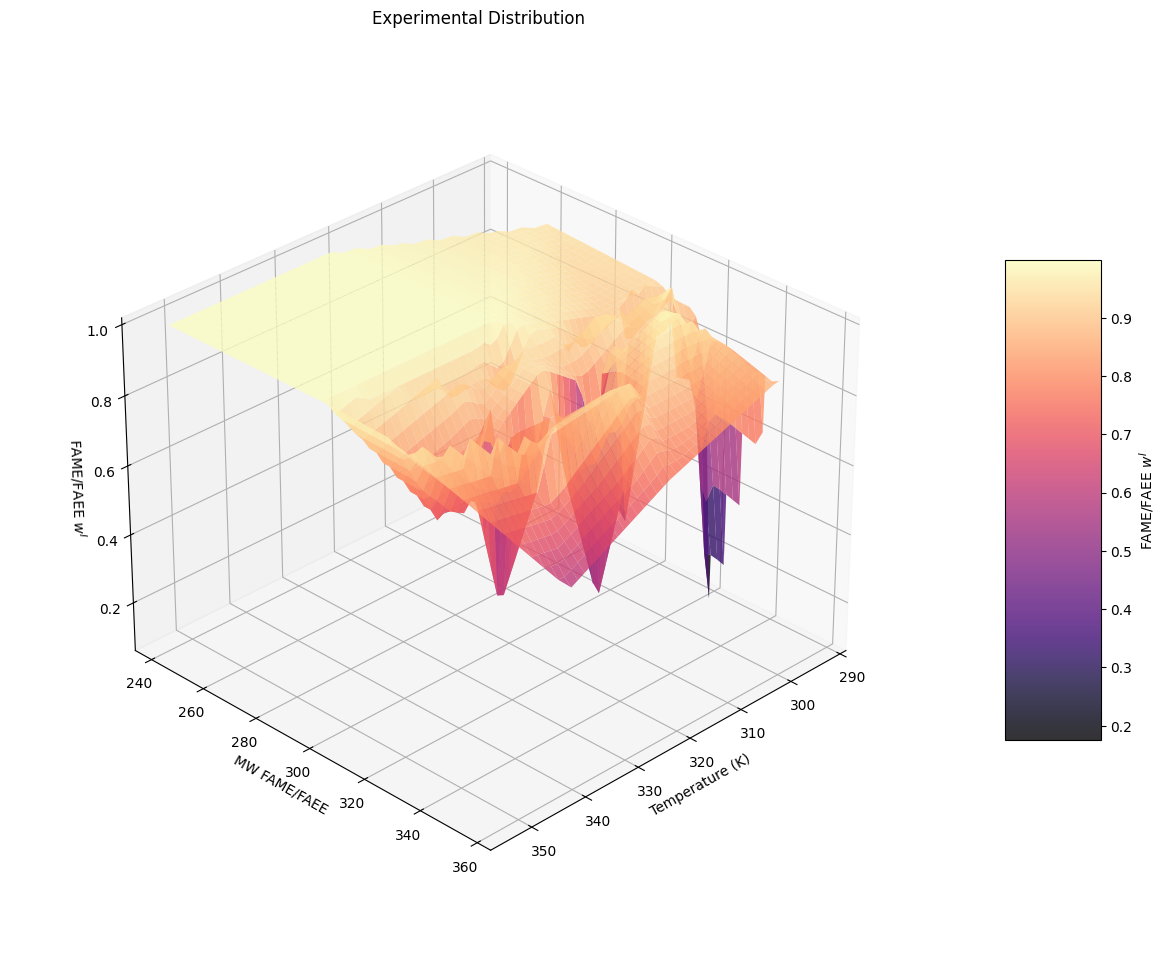

In [ ]:
surface_plot(result_np[0:499, 1], result_np[0:499, 29], result_np[0:499, 11], "Experimental Distribution FAME", "Temperature (K)", "MW FAME/FAEE", "FAME/FAEE $w^I$", "FAME/FAEE $w^I$")

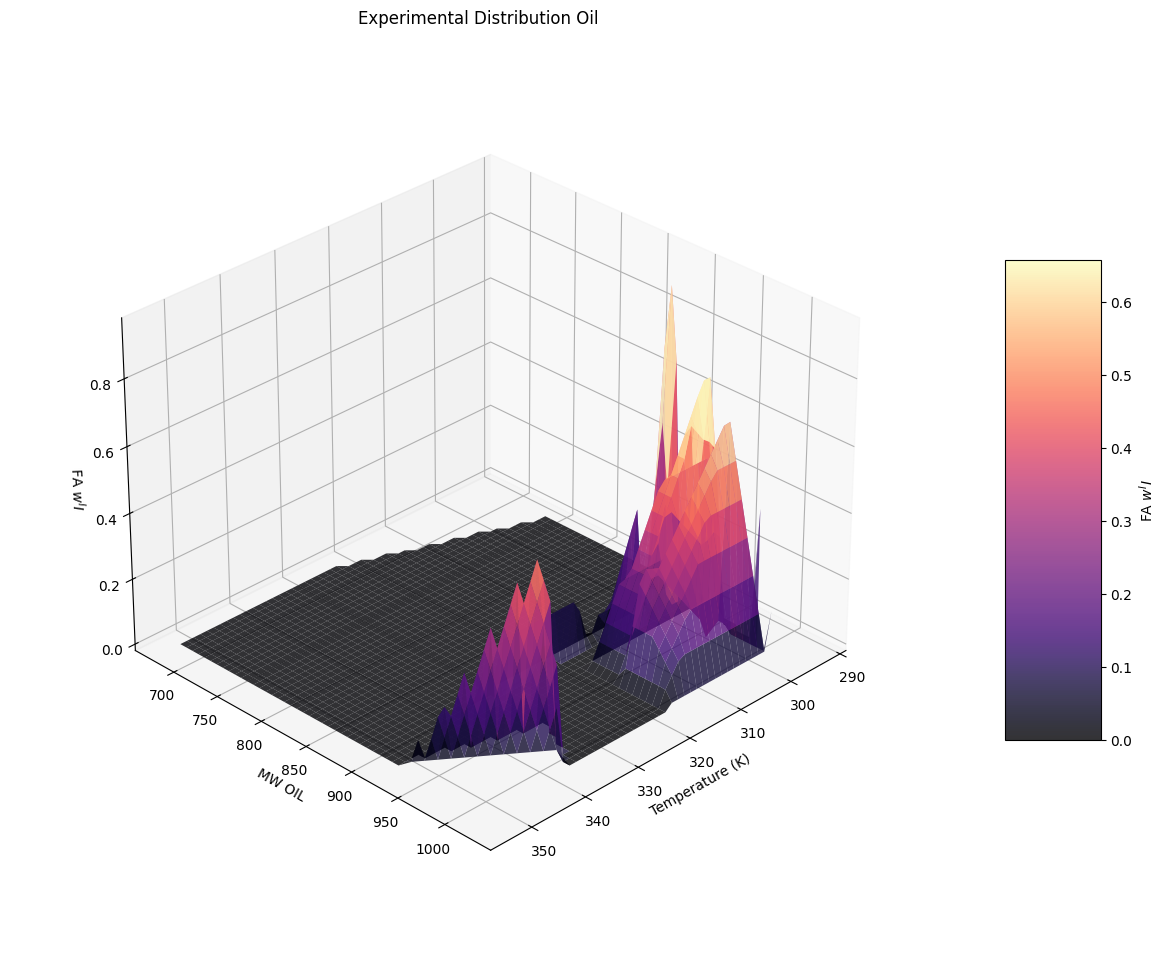

In [125]:
surface_plot(result_np[0:499, 1], result_np[0:499, 32], result_np[0:499, 26], "Experimental Distribution Oil", "Temperature (K)", "MW OIL", " FA $w^II$", "FA $w^II$")